# Figure 15.1 — Velocity saturation, transferred electrons, and impact ionization

High fields invalidate constant mobility, redistribute carriers between valleys, and activate electron–hole pair generation by impact ionization.

## Direct NumPy calculation

The governing relations are evaluated explicitly before the reusable course implementation is imported.

peak transferred-electron velocity = 1.358e+05 m/s
electron ionization rate at max field = 1.504e+05 cm^-1


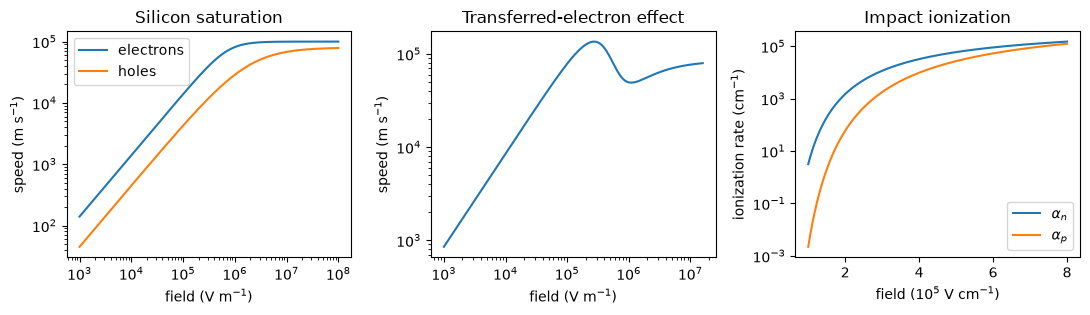

In [1]:
import numpy as np
import matplotlib.pyplot as plt

field = np.logspace(3.0, 8.0, 700)

def saturated_velocity(field, mobility, velocity_limit, exponent):
    reduced = mobility*field/velocity_limit
    return mobility*field/(1+reduced**exponent)**(1/exponent)

v_e = saturated_velocity(field, 0.14, 1e5, 2.0)
v_h = saturated_velocity(field, 0.045, 0.8e5, 1.0)
assert np.isclose(v_e[-1], 1e5, rtol=0.01)

gaas_field = np.logspace(3.0, 7.2, 700)
f_upper = 1/(1+np.exp(-(np.log10(gaas_field)-5.65)/0.12))
v_lower = saturated_velocity(gaas_field, 0.85, 2.1e5, 2.0)
v_upper = saturated_velocity(gaas_field, 0.08, 0.85e5, 1.0)
v_gaas = (1-f_upper)*v_lower + f_upper*v_upper
assert np.any(np.diff(v_gaas) < 0)

impact_field = np.linspace(1e7, 8e7, 600)
alpha_n = 7e7*np.exp(-1.23e8/impact_field)
alpha_p = 1.6e8*np.exp(-2.04e8/impact_field)
assert np.all(np.diff(alpha_n) > 0)

fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
axes[0].loglog(field, v_e, label="electrons")
axes[0].loglog(field, v_h, label="holes")
axes[0].set(xlabel=r"field (V m$^{-1}$)", ylabel=r"speed (m s$^{-1}$)", title="Silicon saturation")
axes[0].legend()
axes[1].loglog(gaas_field, v_gaas)
axes[1].set(xlabel=r"field (V m$^{-1}$)", ylabel=r"speed (m s$^{-1}$)", title="Transferred-electron effect")
axes[2].semilogy(impact_field/1e7, alpha_n/100, label=r"$\alpha_n$")
axes[2].semilogy(impact_field/1e7, alpha_p/100, label=r"$\alpha_p$")
axes[2].set(xlabel=r"field ($10^5$ V cm$^{-1}$)", ylabel=r"ionization rate (cm$^{-1}$)", title="Impact ionization")
axes[2].legend()
print(f"peak transferred-electron velocity = {np.max(v_gaas):.3e} m/s")
print(f"electron ionization rate at max field = {alpha_n[-1]/100:.3e} cm^-1")
fig.tight_layout()
plt.show()

## Reusable publication implementation

The tested course implementation writes the deterministic PDF used by the manuscript.

In [2]:
import sys
from pathlib import Path

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "main.tex").exists()
)
sys.path.insert(0, str(ROOT / "figures" / "src"))

from semphy.transport_extensions import high_field_figure

high_field_figure()
print("wrote transport-high-field.pdf")

wrote transport-high-field.pdf
